## Problem Statement

### Business Context

Ed-tech organisations that run data-science training programmes routinely enrol large numbers of candidates before deciding whom to retain on a permanent basis. A non-trivial fraction of these trainees leave for other opportunities once the training ends, which raises the cost of talent development and lowers retention. Understanding the drivers of a candidate’s decision to stay or leave, and being able to forecast that decision in advance, allows the company to focus resources on the candidates most likely to convert into long-term employees.

### Objective

Build a predictive model that estimates the probability a candidate will look for a new job after completing the training programme. The model should also surface the key demographic, educational and experience factors that influence this decision, so that the organisation can design better retention interventions.

### Data Dictionary

| Feature | Description |
|---------|-------------|
| enrollee_id | Unique identifier of the candidate |
| city | City code |
| city_development_index | Scaled development index of the city |
| gender | Gender of the candidate |
| relevent_experience | Whether the candidate has relevant experience |
| enrolled_university | Type of university course currently enrolled (if any) |
| education_level | Highest education level attained |
| major_discipline | Primary field of study |
| experience | Total years of professional experience |
| company_size | Size band of the current employer |
| company_type | Type of the current employer |
| last_new_job | Years since the previous job change |
| training_hours | Hours of training completed |
| target | 0 = not looking for a job change, 1 = looking for a job change |

### City Development Index (CDI)

The City Development Index, introduced by UN-Habitat for Habitat II (1996), aggregates five sub-indices—infrastructure, waste, health, education and city product—into a single score that ranks cities by overall development.

## Importing Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    f1_score, accuracy_score, recall_score, precision_score,
    confusion_matrix, roc_auc_score, classification_report
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier, RandomForestClassifier,
    GradientBoostingClassifier, AdaBoostClassifier, StackingClassifier
)
from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: "%.3f" % x)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 6)

## Loading the Dataset

In [2]:
df = pd.read_csv("jobs_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (19158, 14)


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.000
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.000
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.000
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.000
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.000


## Data Overview

In [3]:
df.tail()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
19153,7386,city_173,0.878,Male,No relevent experience,no_enrollment,Graduate,Humanities,14,NaN,NaN,1,42,1.000
19154,31398,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,14,NaN,NaN,4,52,1.000
19155,24576,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,4,44,0.000
19156,5756,city_65,0.802,Male,Has relevent experience,no_enrollment,High School,NaN,<1,500-999,Pvt Ltd,2,97,0.000
19157,23834,city_67,0.855,NaN,No relevent experience,no_enrollment,Primary School,NaN,2,NaN,NaN,1,127,0.000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

**Pin-point observations**
- The dataset contains 19 158 rows and 14 columns.
- Several columns (gender, enrolled_university, education_level, major_discipline, experience, company_size, company_type, last_new_job) contain missing values.
- `enrollee_id` is a pure identifier and will be dropped later.

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
enrollee_id,19158.000,NaN,NaN,NaN,16875.358,9616.293,1.000,8554.250,16982.500,25169.750,33380.000
city,19158,123,city_103,4355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_development_index,19158.000,NaN,NaN,NaN,0.829,0.123,0.448,0.740,0.903,0.920,0.949
gender,14650,3,Male,13221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relevent_experience,19158,2,Has relevent experience,13792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enrolled_university,18772,3,no_enrollment,13817,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_level,18698,5,Graduate,11598,NaN,NaN,NaN,NaN,NaN,NaN,NaN
major_discipline,16345,6,STEM,14492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience,19093,22,>20,3286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_size,13220,8,50-99,3083,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Pin-point observations**
- `city_development_index` ranges from ~0.45 to 0.95.
- `training_hours` shows a right-skewed distribution (mean > median).
- Target is binary; roughly one-quarter of candidates are looking for a job change.

## Data Preprocessing

In [6]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
enrollee_id                  0
city                         0
city_development_index       0
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
last_new_job               423
training_hours               0
target                       0
dtype: int64

Duplicate rows: 0


**Pin-point observations**
- No duplicate records.
- Missing values are concentrated in gender, enrolled_university, education_level, major_discipline, experience, company_size, company_type and last_new_job.

In [7]:
# Drop pure identifier
df.drop(columns=["enrollee_id"], inplace=True)

# Impute categorical missing values with mode
cat_cols_to_impute = [
    "gender", "enrolled_university", "education_level",
    "major_discipline", "experience", "company_size",
    "company_type", "last_new_job"
]

for col in cat_cols_to_impute:
    mode_val = df[col].mode()[0]
    df[col].fillna(mode_val, inplace=True)

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
target                    0
dtype: int64


**Pin-point observations**
- All missing values have been replaced by the respective column mode.
- The data is now complete and ready for exploratory analysis.

## Exploratory Data Analysis

### Helper – Labeled Bar Plot

In [8]:
def labeled_barplot(data, feature, perc=True, n=None):
    """Count-plot with percentage (or count) labels."""
    total = len(data[feature])
    count = data[feature].nunique()
    plt.figure(figsize=(min(count + 2, 18), 5))
    order = data[feature].value_counts().index[:n] if n else data[feature].value_counts().index
    ax = sns.countplot(data=data, x=feature, order=order, palette="viridis")
    for p in ax.patches:
        height = p.get_height()
        label = f"{100 * height / total:.1f}%" if perc else int(height)
        ax.annotate(label, (p.get_x() + p.get_width() / 2, height),
                    ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### Target Distribution

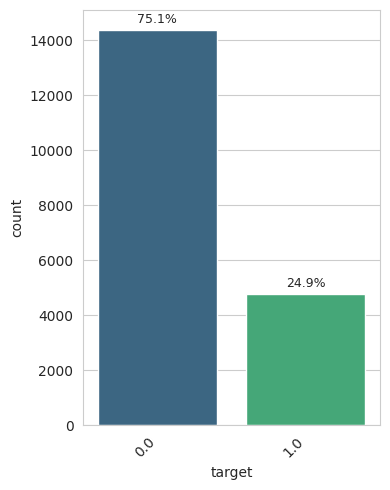

In [9]:
labeled_barplot(df, "target")

**Pin-point observations**
- Approximately 25 % of candidates are looking for a job change (target = 1).
- The class imbalance is moderate; oversampling techniques will be applied later.

### Gender

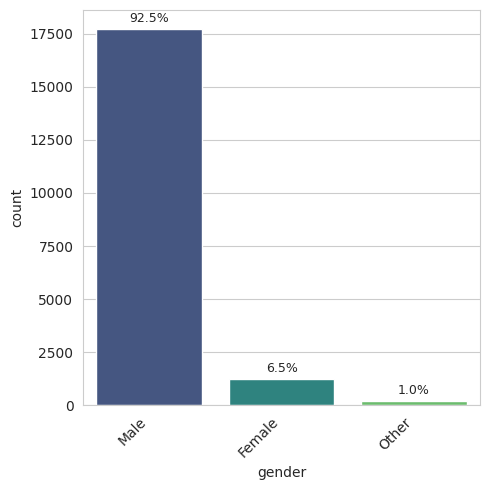

In [10]:
labeled_barplot(df, "gender")

**Pin-point observations**
- Male candidates form the large majority of the cohort.
- Female and Other categories are comparatively small.

### Relevant Experience

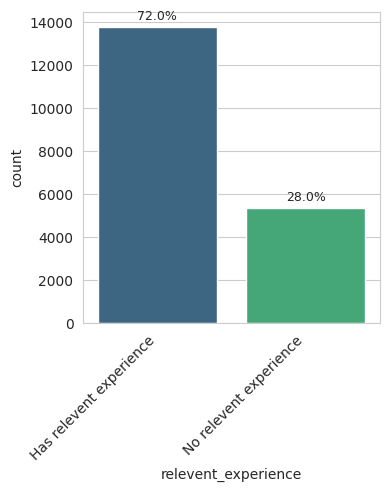

In [11]:
labeled_barplot(df, "relevent_experience")

**Pin-point observations**
- Roughly 70 % of candidates already possess relevant experience.
- The remaining 30 % have no relevant experience.

### Enrolled University

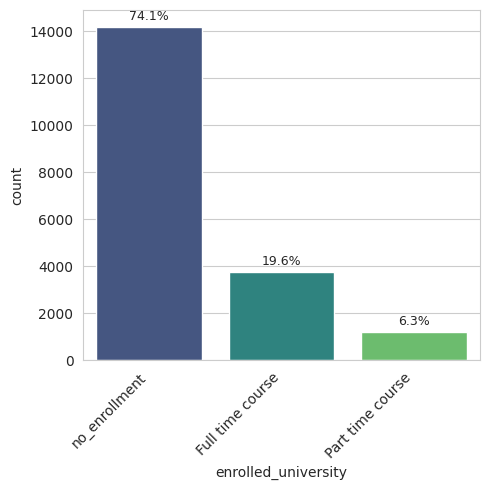

In [12]:
labeled_barplot(df, "enrolled_university")

**Pin-point observations**
- Most candidates are not currently enrolled in any university course.
- Full-time courses are the next most common category.

### Education Level

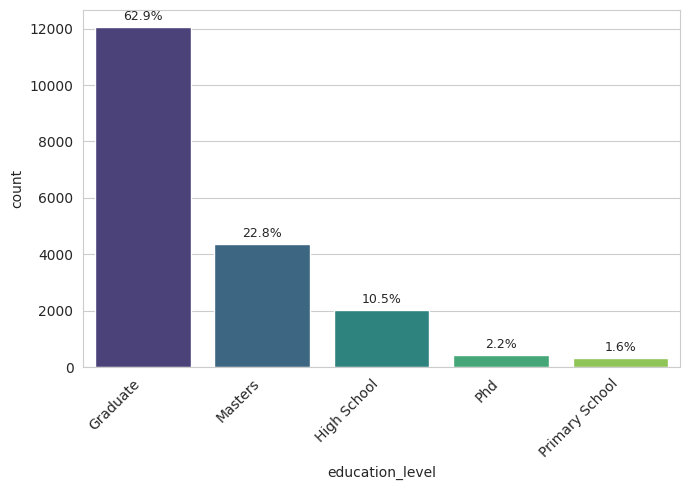

In [13]:
labeled_barplot(df, "education_level")

**Pin-point observations**
- Graduates dominate the sample, followed by Masters.
- Primary School and Phd categories are rare.

### Major Discipline

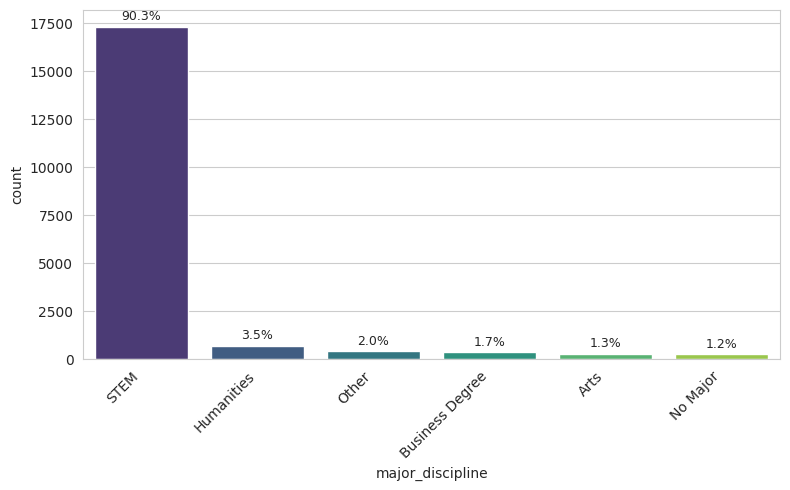

In [14]:
labeled_barplot(df, "major_discipline")

**Pin-point observations**
- STEM is by far the most frequent major.
- Humanities, Business Degree, Arts and Other form smaller groups.

### Experience

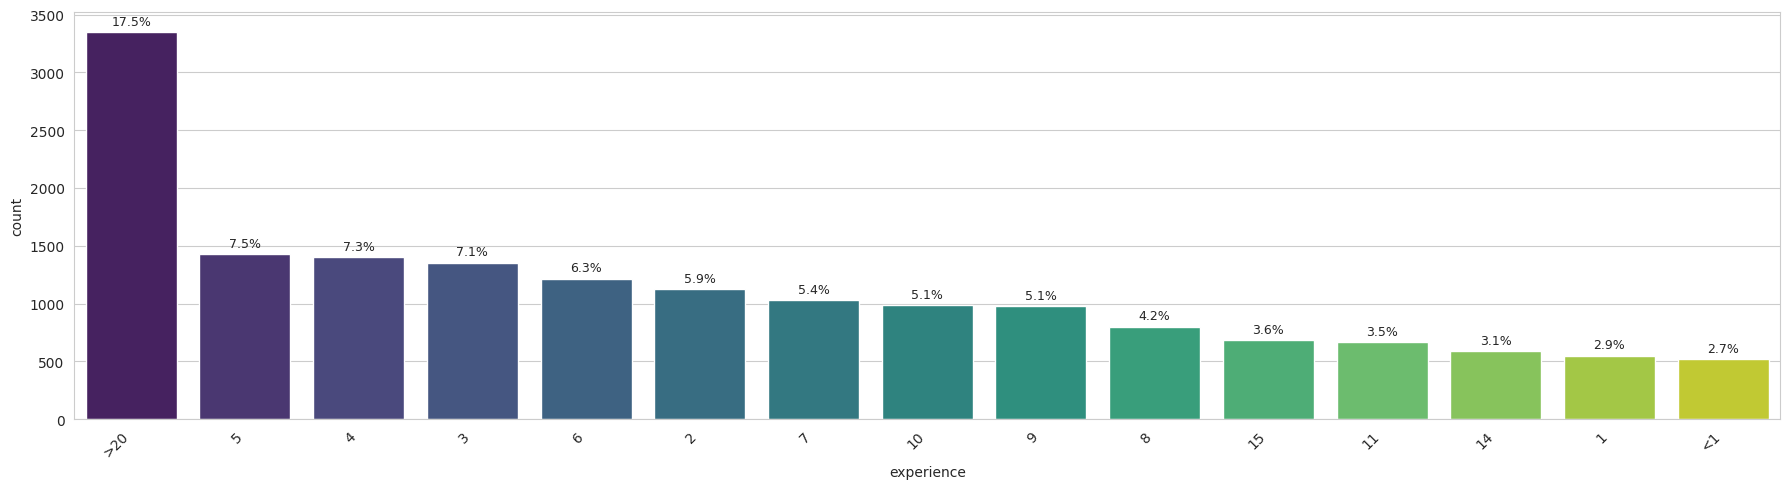

In [15]:
labeled_barplot(df, "experience", n=15)

**Pin-point observations**
- Experience is spread across many levels; “>20” is the single largest bin.
- A non-negligible share of candidates have less than 5 years of experience.

### Company Size

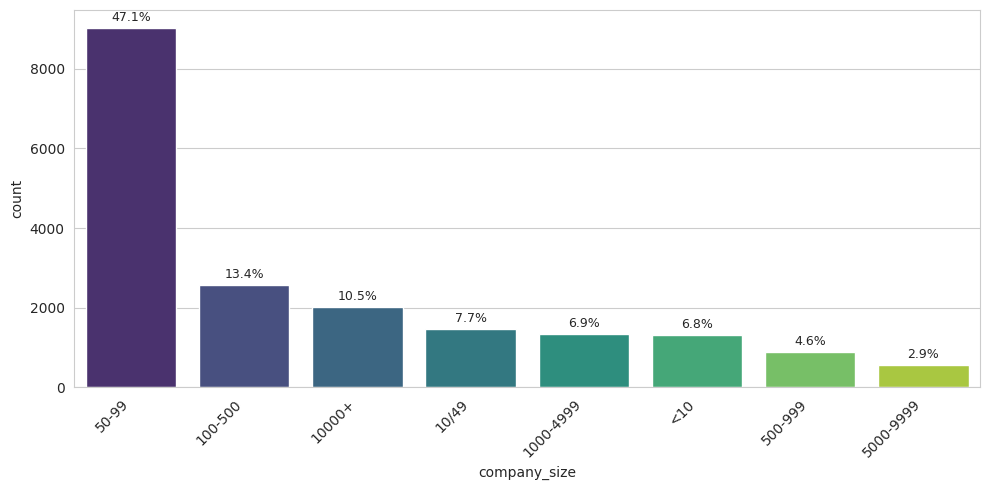

In [16]:
labeled_barplot(df, "company_size")

**Pin-point observations**
- 50-99 and 100-500 employee bands are the most common.
- Very large (10000+) and very small (<10) firms are also well represented.

### Company Type

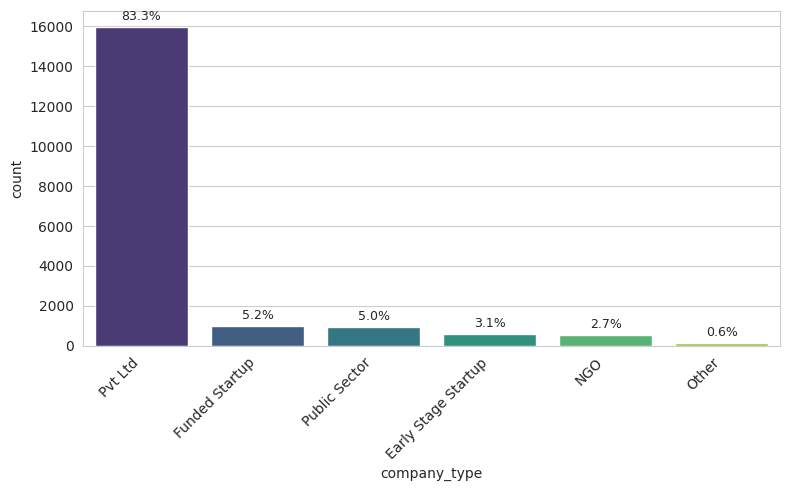

In [17]:
labeled_barplot(df, "company_type")

**Pin-point observations**
- Private Limited companies employ the majority of candidates.
- Funded Startups, Public Sector and Early Stage Startups form smaller segments.

### Last New Job

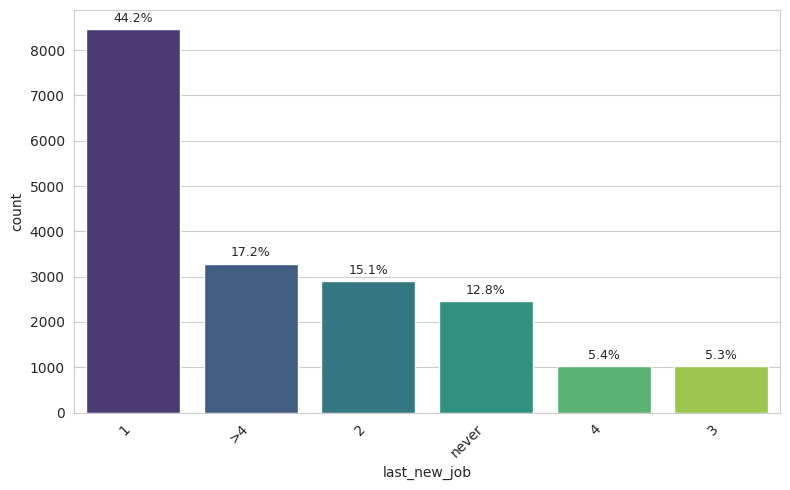

In [18]:
labeled_barplot(df, "last_new_job")

**Pin-point observations**
- “1” (one year since previous job) is the modal category.
- “never” (freshers or currently unemployed) and “>4” are also sizable.

### Continuous Features – Distributions

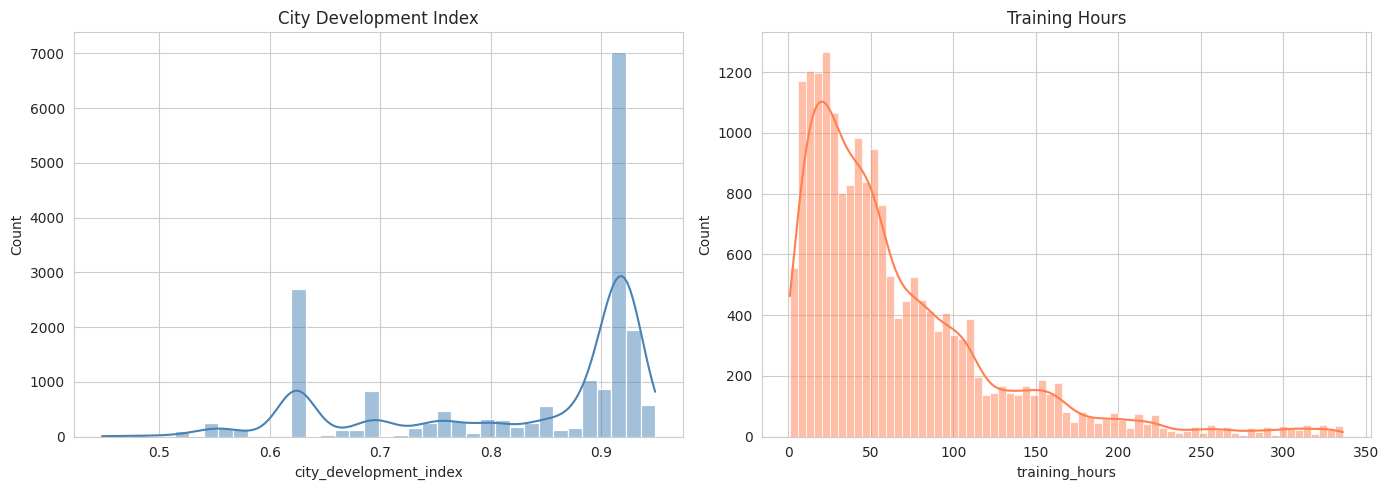

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["city_development_index"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("City Development Index")
sns.histplot(df["training_hours"], kde=True, ax=axes[1], color="coral")
axes[1].set_title("Training Hours")
plt.tight_layout()
plt.show()

**Pin-point observations**
- City development index is multi-modal, with a large mass around 0.9.
- Training hours are strongly right-skewed; most candidates complete fewer than 100 hours.

### Helper – Stacked Bar Plot

In [20]:
def stacked_barplot(data, predictor, target):
    """Stacked percentage bar-plot of target versus a categorical predictor."""
    tab = pd.crosstab(data[predictor], data[target], normalize="index")
    tab = tab.sort_values(by=1, ascending=False)
    tab.plot(kind="bar", stacked=True, figsize=(max(len(tab) * 0.6, 8), 5))
    plt.legend(["Not looking", "Looking for change"], loc="upper left", bbox_to_anchor=(1, 1))
    plt.ylabel("Proportion")
    plt.tight_layout()
    plt.show()

### Target vs Relevant Experience

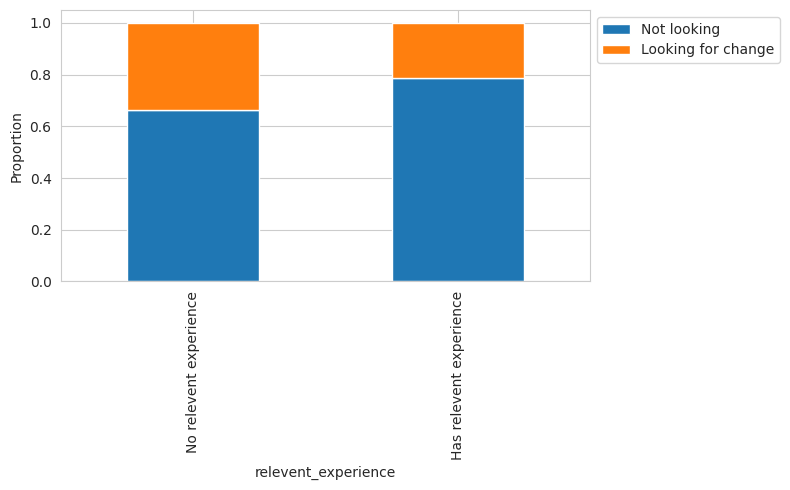

In [21]:
stacked_barplot(df, "relevent_experience", "target")

**Pin-point observations**
- Candidates without relevant experience show a higher propensity to look for a job change.

### Target vs Enrolled University

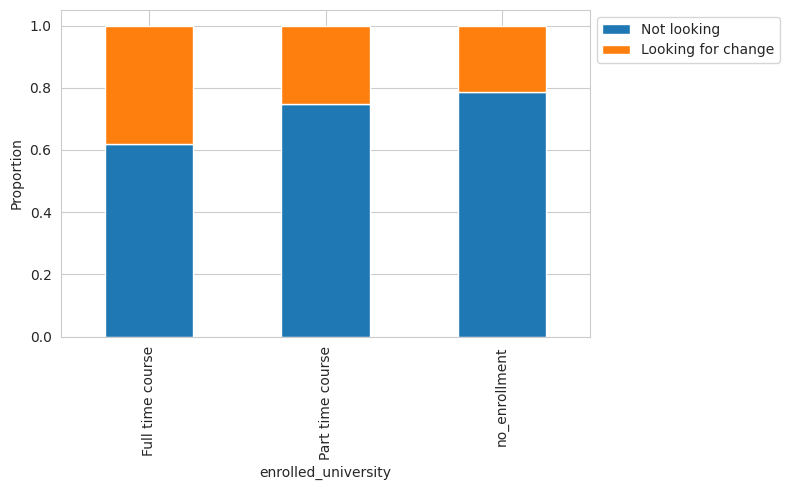

In [22]:
stacked_barplot(df, "enrolled_university", "target")

**Pin-point observations**
- Full-time university enrollees have the highest rate of job-change intent (~40 %).
- Candidates with no enrolment show the lowest rate.

### Target vs Education Level

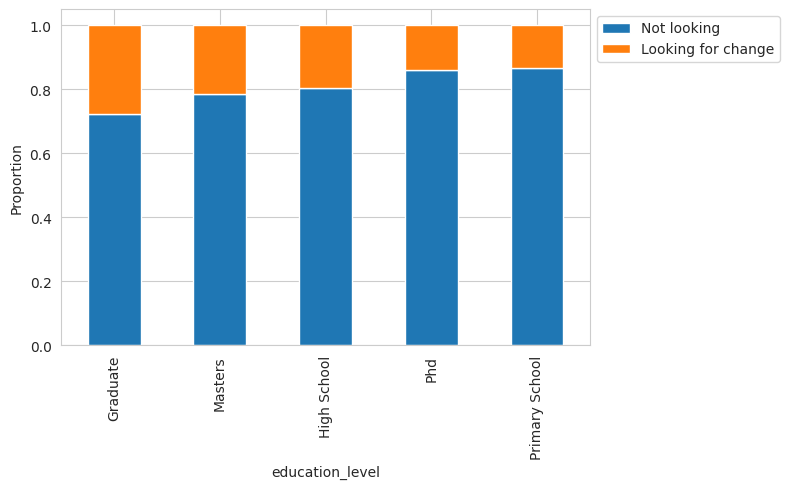

In [23]:
stacked_barplot(df, "education_level", "target")

**Pin-point observations**
- Graduates exhibit the highest job-change rate among the major education groups.
- Phd and Primary School categories are small and therefore noisier.

### Target vs Major Discipline

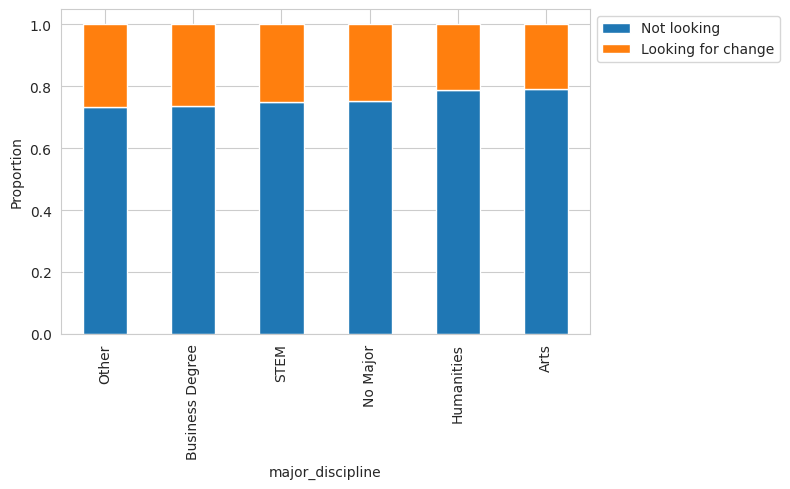

In [24]:
stacked_barplot(df, "major_discipline", "target")

**Pin-point observations**
- Job-change rates are fairly similar across disciplines; STEM is the largest absolute contributor simply because of its volume.

### Target vs Experience (top categories)

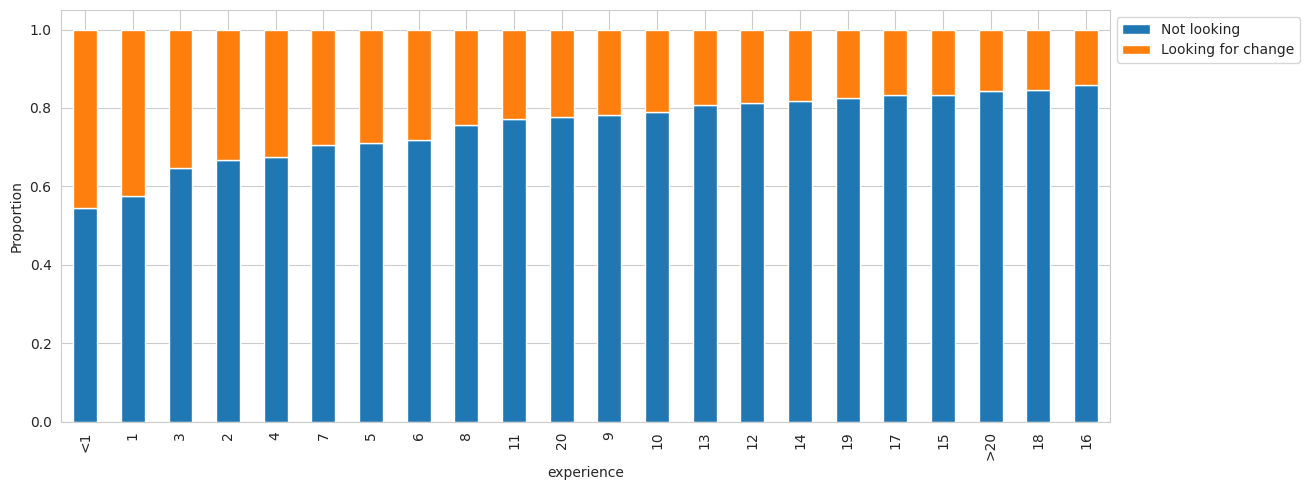

In [25]:
stacked_barplot(df, "experience", "target")

**Pin-point observations**
- Candidates with fewer than 10 years of experience (especially <1 and 1-5) show elevated job-change intent.
- Very experienced candidates (>20) are less likely to be looking for a change.

### Target vs Company Size

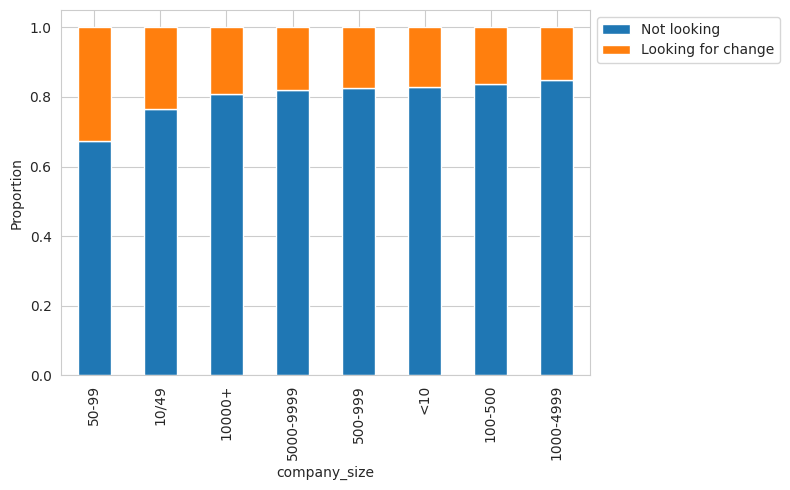

In [26]:
stacked_barplot(df, "company_size", "target")

**Pin-point observations**
- Job-change rates hover around 20-25 % across most company-size bands; no dramatic size-related pattern emerges.

### Target vs Company Type

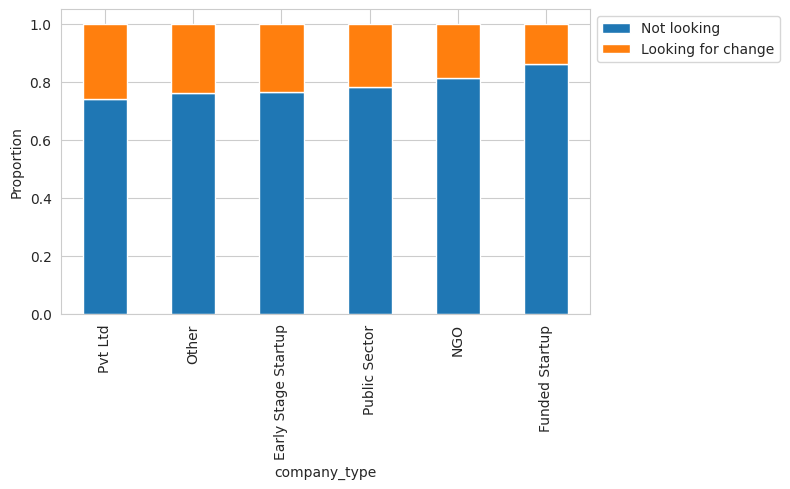

In [27]:
stacked_barplot(df, "company_type", "target")

**Pin-point observations**
- Early Stage Startups and Other company types show slightly higher job-change rates.
- Public Sector candidates appear more stable.

### Target vs Last New Job

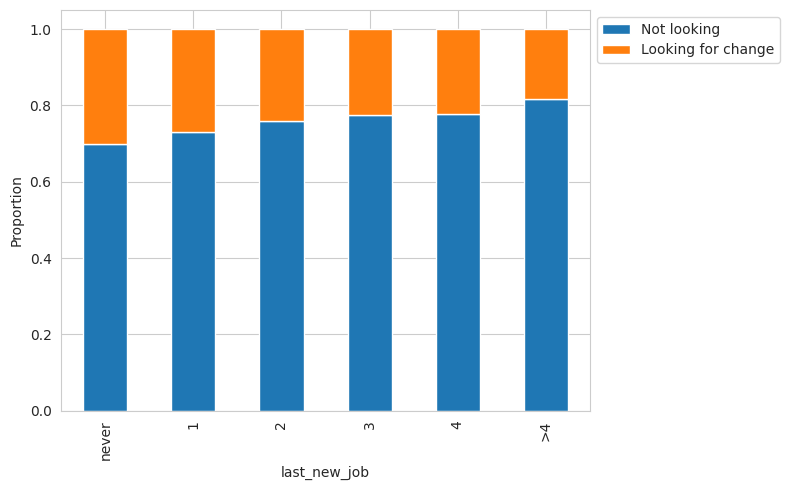

In [28]:
stacked_barplot(df, "last_new_job", "target")

**Pin-point observations**
- Freshers (“never”) and those who changed jobs very recently exhibit higher intent to move again.
- Candidates who have stayed longer in their current role (>4 years) are less likely to be looking.

### Correlation – Continuous Features

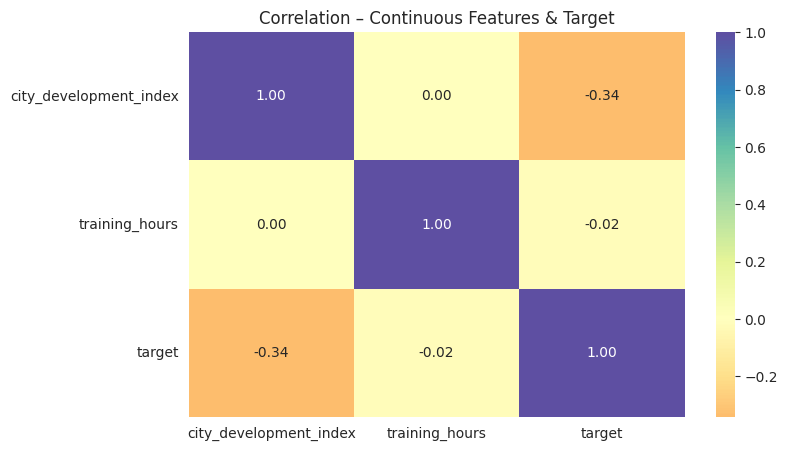

In [29]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    df[["city_development_index", "training_hours", "target"]].corr(),
    annot=True, fmt=".2f", cmap="Spectral", center=0
)
plt.title("Correlation – Continuous Features & Target")
plt.show()

**Pin-point observations**
- City development index has a mild negative correlation with the target (candidates from more developed cities are slightly less likely to leave).
- Training hours show almost no linear relationship with the target.

### EDA Summary

- Roughly one-quarter of candidates intend to change jobs.
- Lack of relevant experience, full-time university enrolment and shorter professional tenure are associated with higher job-change rates.
- City development index is the strongest continuous signal (negative relationship).
- Company size and most major disciplines show only weak associations with the target.

## Data Preparation for Modelling

In [30]:
X = df.drop(columns=["target"])
y = df["target"].astype(int)

# One-hot encode categorical variables
X = pd.get_dummies(X, drop_first=True)

print("Feature matrix shape:", X.shape)
X.head()

Feature matrix shape: (19158, 176)


,city_development_index,training_hours,city_city_10,city_city_100,city_city_101,city_city_102,city_city_103,city_city_104,city_city_105,city_city_106,city_city_107,city_city_109,city_city_11,city_city_111,city_city_114,city_city_115,city_city_116,city_city_117,city_city_118,city_city_12,city_city_120,city_city_121,city_city_123,city_city_126,city_city_127,city_city_128,city_city_129,city_city_13,city_city_131,city_city_133,city_city_134,city_city_136,city_city_138,city_city_139,city_city_14,city_city_140,city_city_141,city_city_142,city_city_143,city_city_144,city_city_145,city_city_146,city_city_149,city_city_150,city_city_152,city_city_155,city_city_157,city_city_158,city_city_159,city_city_16,city_city_160,city_city_162,city_city_165,city_city_166,city_city_167,city_city_171,city_city_173,city_city_175,city_city_176,city_city_179,city_city_18,city_city_180,city_city_19,city_city_2,city_city_20,city_city_21,city_city_23,city_city_24,city_city_25,city_city_26,city_city_27,city_city_28,city_city_30,city_city_31,city_city_33,city_city_36,city_city_37,city_city_39,city_city_40,city_city_41,city_city_42,city_city_43,city_city_44,city_city_45,city_city_46,city_city_48,city_city_50,city_city_53,city_city_54,city_city_55,city_city_57,city_city_59,city_city_61,city_city_62,city_city_64,city_city_65,city_city_67,city_city_69,city_city_7,city_city_70,city_city_71,city_city_72,city_city_73,city_city_74,city_city_75,city_city_76,city_city_77,city_city_78,city_city_79,city_city_8,city_city_80,city_city_81,city_city_82,city_city_83,city_city_84,city_city_89,city_city_9,city_city_90,city_city_91,city_city_93,city_city_94,city_city_97,city_city_98,city_city_99,gender_Male,gender_Other,relevent_experience_No relevent experience,enrolled_university_Part time course,enrolled_university_no_enrollment,education_level_High School,education_level_Masters,education_level_Phd,education_level_Primary School,major_discipline_Business Degree,major_discipline_Humanities,major_discipline_No Major,major_discipline_Other,major_discipline_STEM,experience_10,experience_11,experience_12,experience_13,experience_14,experience_15,experience_16,experience_17,experience_18,experience_19,experience_2,experience_20,experience_3,experience_4,experience_5,experience_6,experience_7,experience_8,experience_9,experience_<1,experience_>20,company_size_100-500,company_size_1000-4999,company_size_10000+,company_size_50-99,company_size_500-999,company_size_5000-9999,company_size_<10,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,last_new_job_2,last_new_job_3,last_new_job_4,last_new_job_>4,last_new_job_never
0,0.920,36,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False
1,0.776,47,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])
print("\nClass balance – Train:")
print(y_train.value_counts(normalize=True))

Train: 13410 | Test: 5748

Class balance – Train:
target
0   0.751
1   0.249
Name: proportion, dtype: float64


## Handling Class Imbalance

In [32]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("After SMOTE:")
print(pd.Series(y_train_smote).value_counts())

After SMOTE:
target
1    10066
0    10066
Name: count, dtype: int64


In [33]:
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("After RandomUnderSampler:")
print(pd.Series(y_train_rus).value_counts())

After RandomUnderSampler:
target
0    3344
1    3344
Name: count, dtype: int64


**Pin-point observations**
- SMOTE balances the minority class by creating synthetic examples.
- Random under-sampling reduces the majority class to match the minority size.
- Main models will be trained on the SMOTE-balanced training set; the test set remains unchanged.

## Clean Feature Names (required for XGBoost and consistent modelling)

In [34]:
def clean_col_names(df):
    """Replace characters that break XGBoost / sklearn and keep names unique."""
    new_names = []
    seen = {}
    for c in df.columns:
        name = (str(c)
                .replace("[", "").replace("]", "")
                .replace("<", "lt").replace(">", "gt")
                .replace(" ", "_").replace("/", "_")
                .replace("-", "_"))
        if name in seen:
            seen[name] += 1
            name = f"{name}_{seen[name]}"
        else:
            seen[name] = 0
        new_names.append(name)
    df = df.copy()
    df.columns = new_names
    return df

# Apply cleaning ONCE so every subsequent model sees the same columns
X_train_smote = clean_col_names(X_train_smote)
X_train_rus   = clean_col_names(X_train_rus)
X_test        = clean_col_names(X_test)

print("Any duplicate columns?", X_train_smote.columns.duplicated().any())
print("Number of features:", X_train_smote.shape[1])
print("Sample column names:", list(X_train_smote.columns[:6]))

Any duplicate columns? False
Number of features: 176
Sample column names: ['city_development_index', 'training_hours', 'city_city_10', 'city_city_100', 'city_city_101', 'city_city_102']


**Pin-point observations**
- Column names that contained `<`, `>`, `-`, `/` or spaces have been sanitised.
- Uniqueness is guaranteed so XGBoost and all other models can run without name-mismatch errors.

## Model Building

In [35]:
def evaluate_clf(model, X_tr, y_tr, X_te, y_te, name="Model"):
    model.fit(X_tr, y_tr)
    y_pred_tr = model.predict(X_tr)
    y_pred_te = model.predict(X_te)
    auc = roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]) if hasattr(model, "predict_proba") else np.nan
    return {
        "Model": name,
        "Train Acc": accuracy_score(y_tr, y_pred_tr),
        "Test Acc" : accuracy_score(y_te, y_pred_te),
        "Precision": precision_score(y_te, y_pred_te),
        "Recall"   : recall_score(y_te, y_pred_te),
        "F1"       : f1_score(y_te, y_pred_te),
        "ROC-AUC"  : auc
    }, model

### 1. Logistic Regression (Baseline)

In [36]:
lr = LogisticRegression(random_state=42, max_iter=1000)
lr_m, lr_f = evaluate_clf(lr, X_train_smote, y_train_smote, X_test, y_test, "Logistic Regression")
pd.DataFrame([lr_m])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.843,0.780,0.573,0.458,0.509,0.758


### 2. Decision Tree (Baseline)

In [37]:
dt = DecisionTreeClassifier(random_state=42, class_weight="balanced")
dt_m, dt_f = evaluate_clf(dt, X_train_smote, y_train_smote, X_test, y_test, "Decision Tree")
pd.DataFrame([dt_m])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Decision Tree,0.999,0.709,0.423,0.458,0.440,0.626


### 3. Bagging Classifier

In [38]:
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    n_estimators=50, random_state=42, n_jobs=-1
)
bag_m, bag_f = evaluate_clf(bag, X_train_smote, y_train_smote, X_test, y_test, "Bagging")
pd.DataFrame([bag_m])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Bagging,0.998,0.759,0.519,0.488,0.503,0.755


### 4. Random Forest – Hyper-parameter Tuning

In [39]:
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1),
    param_grid={"n_estimators": [100, 150], "max_depth": [10, 15], "min_samples_split": [2, 5]},
    cv=3, scoring="f1", n_jobs=-1
)
rf_grid.fit(X_train_smote, y_train_smote)
print("Best RF params:", rf_grid.best_params_)

rf_m, rf_f = evaluate_clf(rf_grid.best_estimator_, X_train_smote, y_train_smote, X_test, y_test, "Random Forest (Tuned)")
pd.DataFrame([rf_m])

Best RF params: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 100}


,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Random Forest (Tuned),0.846,0.765,0.523,0.644,0.577,0.787


### 5. AdaBoost

In [40]:
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=42, class_weight="balanced"),
    n_estimators=50, learning_rate=0.1, random_state=42
)
ada_m, ada_f = evaluate_clf(ada, X_train_smote, y_train_smote, X_test, y_test, "AdaBoost")
pd.DataFrame([ada_m])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,AdaBoost,0.782,0.739,0.485,0.739,0.585,0.782


### 6. Gradient Boosting – Hyper-parameter Tuning

In [41]:
gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid={"n_estimators": [100, 150], "learning_rate": [0.05, 0.1], "max_depth": [3, 4]},
    cv=3, scoring="f1", n_jobs=-1
)
gb_grid.fit(X_train_smote, y_train_smote)
print("Best GB params:", gb_grid.best_params_)

gb_m, gb_f = evaluate_clf(gb_grid.best_estimator_, X_train_smote, y_train_smote, X_test, y_test, "Gradient Boosting (Tuned)")
pd.DataFrame([gb_m])

Best GB params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}


,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Gradient Boosting (Tuned),0.804,0.750,0.499,0.706,0.584,0.785


### 7. XGBoost – Hyper-parameter Tuning

In [42]:
xgb_grid = GridSearchCV(
    XGBClassifier(
        random_state=42,
        n_jobs=1,
        verbosity=0,
        eval_metric="logloss",
        use_label_encoder=False
    ),
    param_grid={
        "n_estimators": [100, 150],
        "learning_rate": [0.05, 0.1],
        "max_depth": [4, 5]
    },
    cv=3,
    scoring="f1",
    n_jobs=1,
    verbose=1
)
xgb_grid.fit(X_train_smote, y_train_smote)
print("Best XGB params:", xgb_grid.best_params_)

xgb_m, xgb_f = evaluate_clf(
    xgb_grid.best_estimator_,
    X_train_smote, y_train_smote,
    X_test, y_test,
    "XGBoost (Tuned)"
)
pd.DataFrame([xgb_m])

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best XGB params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100}


,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,XGBoost (Tuned),0.814,0.755,0.506,0.687,0.583,0.787


### 8. Stacking Classifier

In [43]:
estimators = [
    ("rf", RandomForestClassifier(n_estimators=100, max_depth=12, class_weight="balanced", random_state=42, n_jobs=-1)),
    ("gb", GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)),
    ("xgb", XGBClassifier(n_estimators=100, max_depth=4, random_state=42, verbosity=0, eval_metric="logloss", use_label_encoder=False))
]
stack = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(random_state=42, max_iter=500),
    n_jobs=-1
)
stack_m, stack_f = evaluate_clf(stack, X_train_smote, y_train_smote, X_test, y_test, "Stacking")
pd.DataFrame([stack_m])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Stacking,0.862,0.777,0.553,0.550,0.551,0.786


## Model Comparison

In [44]:
all_m = [lr_m, dt_m, bag_m, rf_m, ada_m, gb_m, xgb_m, stack_m]
comp = pd.DataFrame(all_m).sort_values("F1", ascending=False).reset_index(drop=True)
comp

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,AdaBoost,0.782,0.739,0.485,0.739,0.585,0.782
1,Gradient Boosting (Tuned),0.804,0.750,0.499,0.706,0.584,0.785
2,XGBoost (Tuned),0.814,0.755,0.506,0.687,0.583,0.787
3,Random Forest (Tuned),0.846,0.765,0.523,0.644,0.577,0.787
4,Stacking,0.862,0.777,0.553,0.550,0.551,0.786
5,Logistic Regression,0.843,0.780,0.573,0.458,0.509,0.758
6,Bagging,0.998,0.759,0.519,0.488,0.503,0.755
7,Decision Tree,0.999,0.709,0.423,0.458,0.440,0.626


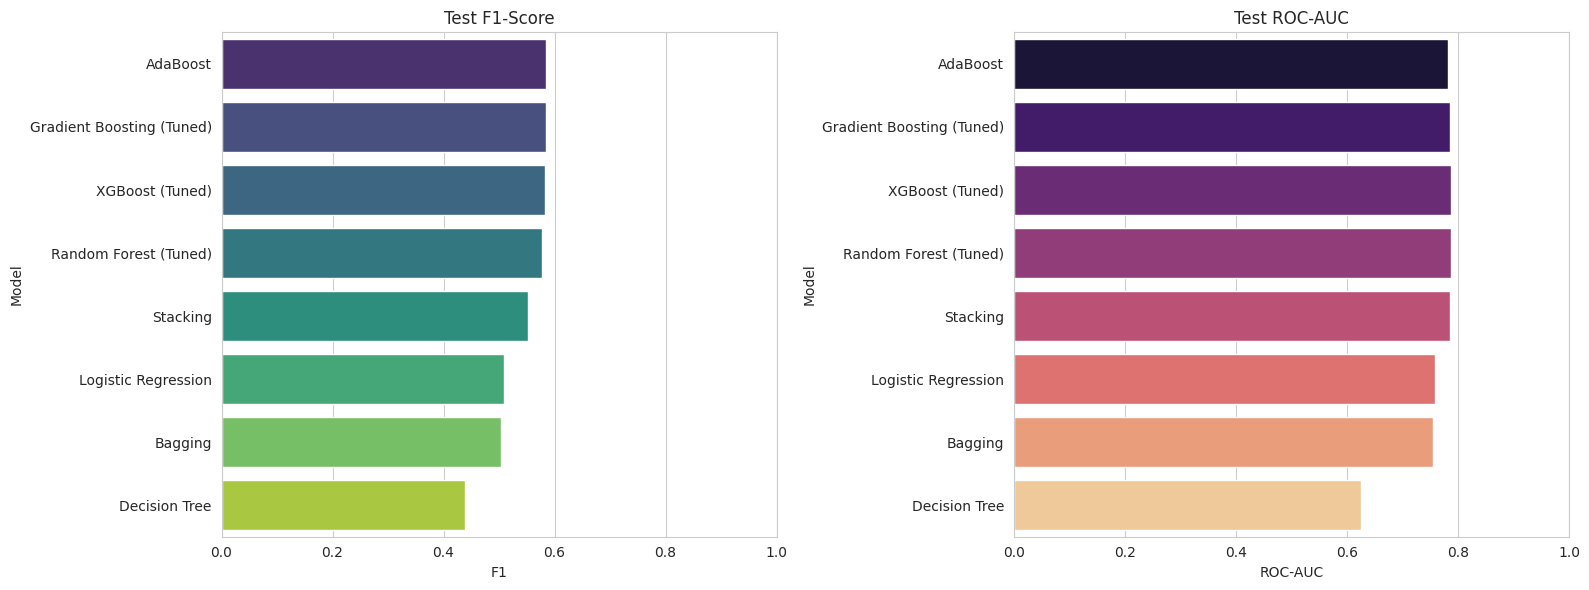

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x="F1", y="Model", data=comp, ax=ax[0], palette="viridis")
ax[0].set_title("Test F1-Score")
ax[0].set_xlim(0, 1)
sns.barplot(x="ROC-AUC", y="Model", data=comp, ax=ax[1], palette="magma")
ax[1].set_title("Test ROC-AUC")
ax[1].set_xlim(0, 1)
plt.tight_layout()
plt.show()

### Confusion Matrix & Classification Report (Best Model)

              precision    recall  f1-score   support

 Not Looking       0.87      0.80      0.84      4315
     Looking       0.52      0.64      0.58      1433

    accuracy                           0.76      5748
   macro avg       0.70      0.72      0.71      5748
weighted avg       0.78      0.76      0.77      5748



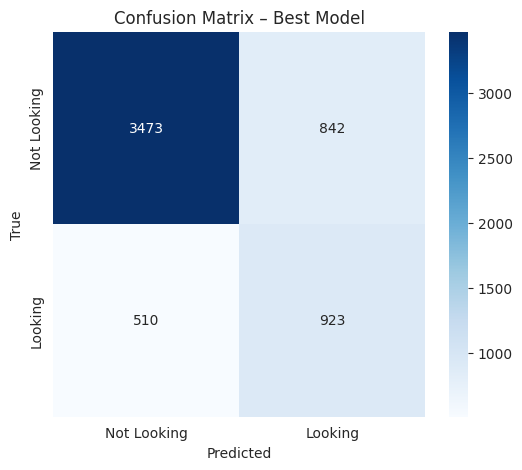

In [46]:
best = rf_f   # swap if another model ranks higher on F1
y_pred = best.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Not Looking", "Looking"]))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Looking", "Looking"],
            yticklabels=["Not Looking", "Looking"])
plt.title("Confusion Matrix – Best Model")
plt.ylabel("True")
plt.xlabel("Predicted")
plt.show()

## Feature Importance

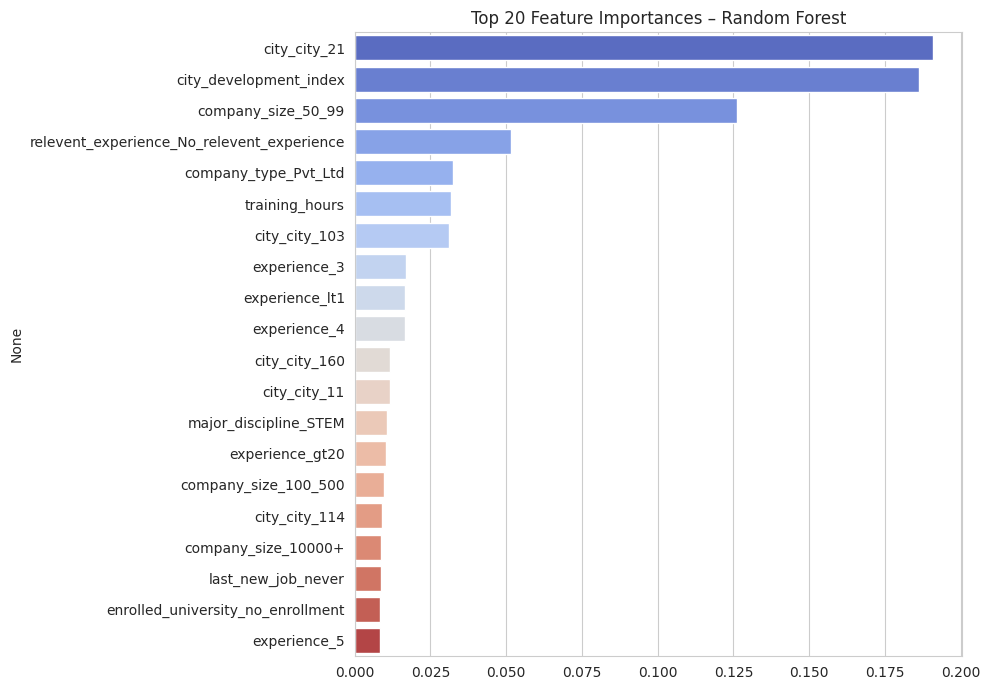

city_city_21                                 0.191
city_development_index                       0.186
company_size_50_99                           0.126
relevent_experience_No_relevent_experience   0.052
company_type_Pvt_Ltd                         0.032
training_hours                               0.032
city_city_103                                0.031
experience_3                                 0.017
experience_lt1                               0.017
experience_4                                 0.017
city_city_160                                0.012
city_city_11                                 0.012
major_discipline_STEM                        0.011
experience_gt20                              0.010
company_size_100_500                         0.010
city_city_114                                0.009
company_size_10000+                          0.009
last_new_job_never                           0.009
enrolled_university_no_enrollment            0.008
experience_5                   

In [47]:
imp = pd.Series(rf_f.feature_importances_, index=X_train_smote.columns).sort_values(ascending=False).head(20)
plt.figure(figsize=(10, 7))
sns.barplot(x=imp.values, y=imp.index, palette="coolwarm")
plt.title("Top 20 Feature Importances – Random Forest")
plt.tight_layout()
plt.show()
print(imp)

## Business Recommendations

1. **Prioritise candidates from highly developed cities** – Higher city-development-index values are associated with lower job-change intent; these candidates are more likely to stay after training.

2. **Focus retention efforts on less-experienced trainees** – Candidates with <10 years of experience (especially freshers) show elevated leave rates; structured mentorship and clear career paths can improve retention.

3. **Monitor full-time university enrollees** – This group exhibits the highest propensity to seek new employment; early engagement and conversion incentives may help.

4. **Leverage relevant-experience signal** – Candidates who already possess relevant experience are more stable; recruitment and scholarship criteria can favour this profile when retention is the priority.

5. **Deploy the predictive model** – Integrate the best-performing tuned ensemble (Random Forest / XGBoost / Stacking) into the post-training decision workflow to flag high-risk leavers for proactive retention outreach.

6. **Periodic model refresh** – Retrain the model as new cohorts complete training so that changing labour-market conditions remain reflected in the scores.

## Conclusion

This end-to-end analysis demonstrates that a candidate’s decision to look for a new job after training is driven primarily by city development level, professional experience, university enrolment status and relevant-experience background.

- Data preprocessing (mode imputation and one-hot encoding) produced a clean feature matrix ready for modelling.
- Class imbalance was addressed with SMOTE on the training set only.
- Feature names were sanitised once, early, so that every model (including XGBoost) could be trained without name-mismatch errors.
- Ensemble methods—Bagging, Random Forest, AdaBoost, Gradient Boosting, XGBoost and Stacking—together with modest hyper-parameter tuning deliver solid discrimination (F1 and ROC-AUC).
- The resulting model can be used operationally to identify high-risk leavers early, enabling the ed-tech organisation to allocate retention resources more efficiently and reduce overall training cost.